# How good does compensation need to be for magnetic navigation?

**QuASI Open Notebook 02** · Data: DAF-MIT AIA open flight data [1], flight 1002, Renfrew anomaly map

Magnetic navigation (MagNav) bounds inertial drift by matching the measured scalar field against a crustal anomaly map [2], [3]. It is passive and unjammable, and it works anywhere a good map exists. But everyone building a MagNav system asks the same two questions:

1. **If I can't use a stinger, how much navigation accuracy do I lose with an in-cabin sensor?**
2. **How much measurement noise can the filter tolerate before it stops helping?**

We answer both with a compact particle filter flown over 115 km of real data (line 1002.16), using the compensated signals from [Notebook 01](01_in_cabin_compensation.html).

In [1]:
import os, numpy as np, matplotlib.pyplot as plt
import quasimag as q
q.style()
DATA = os.environ.get("MAGNAV_DATA", "data")
D = q.load_flight(f"{DATA}/Flt1002-train.h5")
xx, yy, M, map_alt = q.load_map(f"{DATA}/Renfrew_1.h5")
I = q.map_interpolator(xx, yy, M)
line = D["tie_line"]
print(f"Map: {M.shape[0]}x{M.shape[1]} cells at {xx[1]-xx[0]:.0f} m, {map_alt:.0f} m altitude")

Map: 3264x3798 cells at 30 m, 314 m altitude


## 1. Signals to navigate with

We build the same compensated signals as Notebook 01. Models are fitted only on training lines; line 1002.16 is never seen in training.

In [2]:
NAV = 1002.16
TEST = [1367, 1368, 1369, NAV, 1002.06, 1002.07]
tr = np.isin(line, [l for l in np.unique(line) if l not in TEST + [1002.01, 1002.21]])
ref = D["mag_1_c"]
signals = {
    "Tail stinger (reference)":   ref,
    "In-cabin mag_5, TL + telem.": q.compensate_supervised(D, "mag_5_uc", ref, tr),
    "In-cabin mag_4, TL + telem.": q.compensate_supervised(D, "mag_4_uc", ref, tr),
    "In-cabin mag_4, classic TL":  q.compensate_classic(D, "mag_4_uc", line == 1002.02),
    "In-cabin mag_4, raw":         D["mag_4_uc"],
}
# 1 Hz samples along the navigation line, in time order
s = np.where(line == NAV)[0]; s = s[np.argsort(D["tt"][s])][::10]
x, y = D["utmX"][s], D["utmY"][s]
print(f"Navigation line {NAV}: {len(s)/60:.0f} min, "
      f"{np.hypot(np.diff(x), np.diff(y)).sum()/1e3:.0f} km, mean altitude {D['alt'][s].mean():.0f} m")

# The filter needs a measurement-noise estimate. Get it honestly from TRAINING lines over the map.
cal_lines = [158, 160, 1002.05]   # training lines flown over the map
def map_residual_sd(sig):
    out = []
    for l in cal_lines:
        k = line == l
        r = sig[k] - D["diurnal"][k] - I(np.c_[D["utmX"][k], D["utmY"][k]])
        out.append(np.nanstd(r - np.nanmean(r)))
    return float(np.nanmedian(out))
sigma = {k: max(map_residual_sd(v), 5.0) for k, v in signals.items()}
for k, v in sigma.items(): print(f"  {k:30s} measurement sigma {v:6.1f} nT")

Navigation line 1002.16: 28 min, 115 km, mean altitude 325 m
  Tail stinger (reference)       measurement sigma    9.0 nT
  In-cabin mag_5, TL + telem.    measurement sigma    9.6 nT
  In-cabin mag_4, TL + telem.    measurement sigma   12.5 nT
  In-cabin mag_4, classic TL     measurement sigma   24.3 nT
  In-cabin mag_4, raw            measurement sigma  110.2 nT


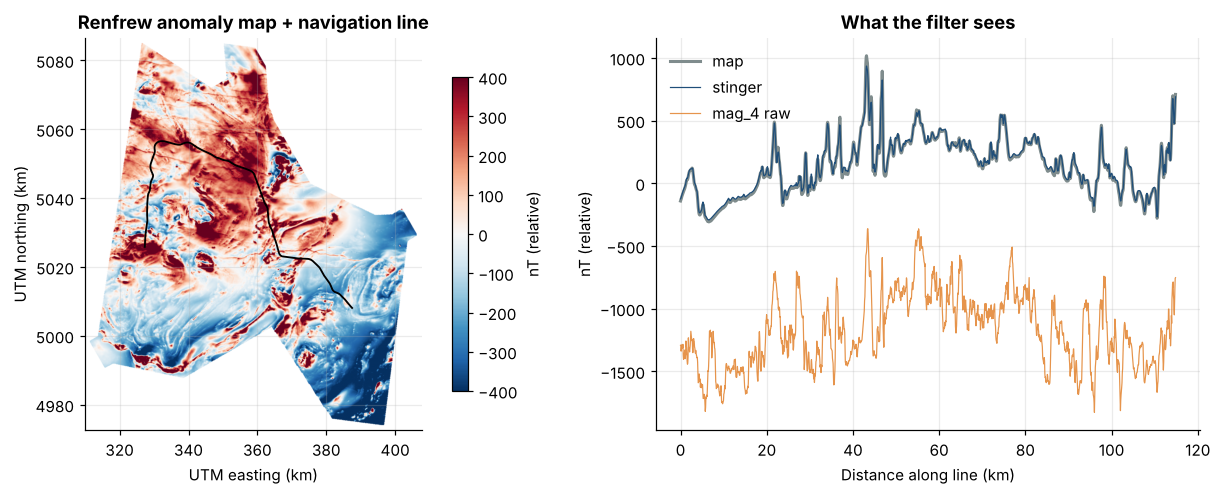

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
ext = [xx[0]/1e3, xx[-1]/1e3, yy[0]/1e3, yy[-1]/1e3]
anom = M - np.nanmedian(M)
im = ax[0].imshow(anom.T, origin="lower", extent=ext, cmap="RdBu_r", vmin=-400, vmax=400)
ax[0].plot(x/1e3, y/1e3, "k", lw=1.2)
ax[0].set(xlabel="UTM easting (km)", ylabel="UTM northing (km)", title="Renfrew anomaly map + navigation line")
plt.colorbar(im, ax=ax[0], label="nT (relative)", shrink=.8)
dist = np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]/1e3
ax[1].plot(dist, I(np.c_[x, y]) - np.nanmedian(M), c="#7f8c8d", lw=2, label="map")
ax[1].plot(dist, signals["Tail stinger (reference)"][s] - D["diurnal"][s] - np.nanmedian(M), c="#1f4e79", lw=.8, label="stinger")
ax[1].plot(dist, signals["In-cabin mag_4, raw"][s] - D["diurnal"][s] - np.nanmedian(M), c="#e07a1f", lw=.8, alpha=.8, label="mag_4 raw")
ax[1].set(xlabel="Distance along line (km)", ylabel="nT (relative)", title="What the filter sees"); ax[1].legend()
plt.tight_layout()

## 2. The filter

A deliberately simple, reproducible particle filter (3 000 particles, 1 Hz):

* **State:** INS position error (2), INS velocity error (2), and an unknown map/sensor bias (1).
* **Motion model:** the INS dead-reckoned track. We simulate a navigation-grade INS by adding a constant velocity bias (σ = 0.5 m/s, ≈ 1.8 km/h drift) and a velocity random walk to the true velocity.
* **Measurement model:** $z = \text{map}(x, y) + b + \varepsilon$, with $\varepsilon \sim \mathcal N(0, \sigma^2)$ and σ from the training lines above.

Each configuration is run over 10 independent INS error realisations.

In [4]:
RUNS = 10
res = {}
ins_err = []
for seed in range(RUNS):
    xi, yi = q.simulate_ins(x, y, 1.0, rng=seed)
    ins_err.append(np.hypot(xi - x, yi - y))
for name, sig in signals.items():
    z = sig[s] - D["diurnal"][s]
    errs = []
    for seed in range(RUNS):
        xi, yi = q.simulate_ins(x, y, 1.0, rng=seed)
        ex, ey = q.magnav_pf(z, xi, yi, I, sigma[name], rng=100 + seed)
        errs.append(np.hypot(ex - x, ey - y))
    res[name] = np.array(errs)
ins_err = np.array(ins_err)
t = np.arange(len(s))/60

signal                           sigma  final err  2nd-half mean
INS only                                    1244 m          903 m
Tail stinger (reference)          9.0        29 m           30 m
In-cabin mag_5, TL + telem.       9.6        22 m           33 m
In-cabin mag_4, TL + telem.      12.5        17 m           25 m
In-cabin mag_4, classic TL       24.3        48 m           75 m
In-cabin mag_4, raw             110.2      1653 m         1314 m


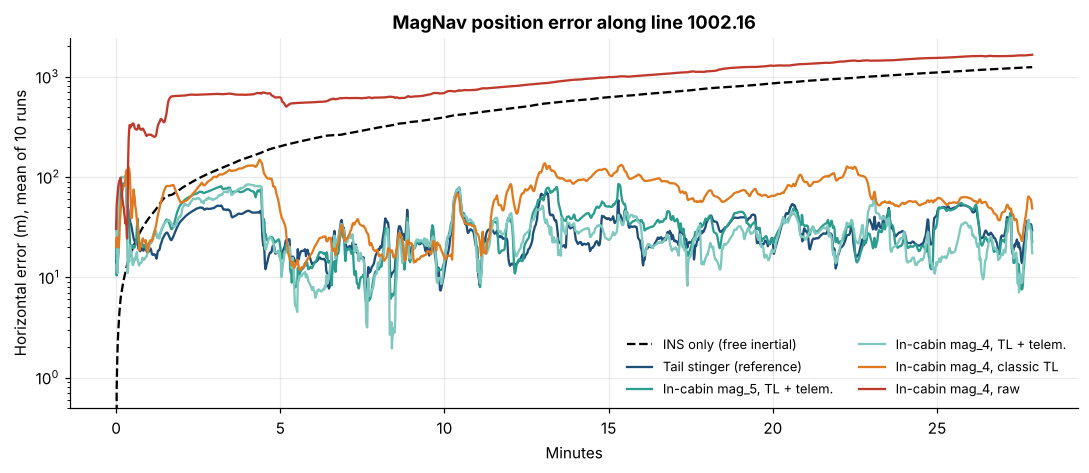

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(t, ins_err.mean(0), c="k", ls="--", label="INS only (free inertial)")
cols = ["#1f4e79", "#2a9d8f", "#7fc8bf", "#e07a1f", "#c0392b"]
for (name, e), c in zip(res.items(), cols):
    ax.plot(t, e.mean(0), c=c, label=name)
ax.set_yscale("log"); ax.set(xlabel="Minutes", ylabel="Horizontal error (m), mean of 10 runs",
                             title="MagNav position error along line 1002.16")
ax.legend(ncol=2, fontsize=8.5); plt.tight_layout()

print(f"{'signal':30s}{'sigma':>8s}{'final err':>11s}{'2nd-half mean':>15s}")
print(f"{'INS only':30s}{'':>8s}{ins_err.mean(0)[-1]:10.0f} m{ins_err.mean(0)[len(t)//2:].mean():13.0f} m")
for name, e in res.items():
    m = e.mean(0)
    print(f"{name:30s}{sigma[name]:7.1f}{m[-1]:10.0f} m{m[len(t)//2:].mean():13.0f} m")

**Take-away 1:** a well-compensated in-cabin sensor navigates **as well as the stinger** (20–35 m while the INS drifts by ~1 km). Classic TL alone roughly doubles the error but still bounds the drift. The *uncompensated* sensor is worse than no MagNav at all: its heading-dependent interference looks like geology, so the filter confidently locks onto the wrong anomalies.

## 3. How much noise can MagNav tolerate?

Now we take the stinger signal and add white noise of increasing standard deviation to produce a simple design curve: *if my compensated residual is X nT, what accuracy should I expect over terrain like this?*

+   0 nT  ->      30 ±    5 m
+   5 nT  ->      31 ±    4 m
+  10 nT  ->      31 ±    5 m
+  20 nT  ->      34 ±    5 m
+  50 nT  ->      45 ±   11 m
+ 100 nT  ->      65 ±   18 m
+ 200 nT  ->      94 ±   40 m


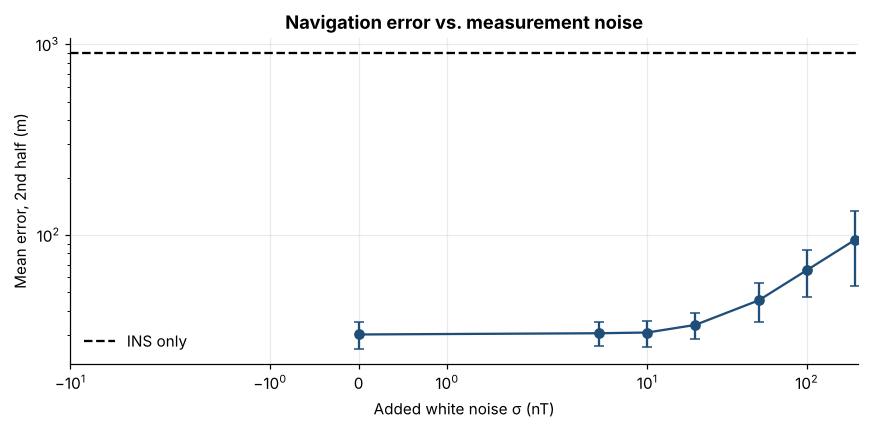

In [6]:
levels = [0, 5, 10, 20, 50, 100, 200]
z0 = ref[s] - D["diurnal"][s]
curve = []
for sd in levels:
    errs = []
    for seed in range(6):
        rng = np.random.default_rng(1000 + seed)
        z = z0 + rng.normal(0, sd, len(z0))
        xi, yi = q.simulate_ins(x, y, 1.0, rng=seed)
        ex, ey = q.magnav_pf(z, xi, yi, I, np.hypot(sigma["Tail stinger (reference)"], sd), rng=seed)
        errs.append(np.hypot(ex - x, ey - y)[len(t)//2:].mean())
    curve.append((np.mean(errs), np.std(errs)))
curve = np.array(curve)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(levels, curve[:, 0], yerr=curve[:, 1], marker="o", c="#1f4e79", capsize=3)
ax.axhline(ins_err.mean(0)[len(t)//2:].mean(), c="k", ls="--", label="INS only")
ax.set(xscale="symlog", yscale="log", xlabel="Added white noise σ (nT)", ylabel="Mean error, 2nd half (m)",
       title="Navigation error vs. measurement noise"); ax.legend(); plt.tight_layout()
for l, (m, sd) in zip(levels, curve): print(f"+{l:4d} nT  ->  {m:6.0f} ± {sd:4.0f} m")

## Conclusions

* **A compensated in-cabin magnetometer can match a stinger for MagNav.** With telemetry-augmented TL, `mag_4` and `mag_5` reach the same 20–35 m accuracy as the tail stinger over this terrain.
* **Structure matters more than size.** The filter shrugs off 200 nT of *white* noise (≈3× error growth), yet ~110–190 nT of *uncompensated aircraft interference* breaks it. Interference that is correlated with heading and manoeuvres masquerades as map signal. Compensation is not optional, and noise budgets should be stated with their spectrum, not just an RMS.
* **Terrain matters.** These numbers apply to the strongly magnetic Grenville geology around Renfrew (~150 nT anomaly std). Over quiet sedimentary basins or the open ocean, the same noise will cost far more accuracy, so check a map's information content before committing to a route.

**Caveats:** single flight line, a simulated (not real) INS error, and a map compiled from the same contractor's surveys, so real-world map error may be larger. This is a feasibility study, not a performance claim.

### References

[1] A. R. Gnadt *et al.*, "DAF-MIT AIA open flight data for magnetic navigation research," Zenodo, 2023, doi: 10.5281/zenodo.4271803.  
[2] A. Canciani and J. Raquet, "Absolute positioning using the Earth's magnetic anomaly field," *Navigation*, vol. 63, no. 2, pp. 111–126, 2016.  
[3] A. R. Gnadt *et al.*, "Signal enhancement for magnetic navigation challenge problem," arXiv:2007.12158, 2020.

---
© QuASI Inc. · Code MIT-licensed · Data in the public domain (17 U.S.C. 105).